# Aula 4 — Agrupamento (clustering) e similaridade espectral
**Módulo `geocis_espectral.agrupamento`**

Agrupamento é **não supervisionado**: os grupos saem só dos espectros, sem usar os atributos.
Depois *interpretamos* os grupos com os atributos (perfil por cluster) — é assim que se
chega a "padrões espectrais" de solos (ex.: os padrões de Demattê/Poppiel).

Roteiro: espaço de trabalho (PCs) → k-means e escolha de k → ISODATA → métricas de
similaridade (SAM, SID, SCM, Euclidiana) → classificação por espectros de referência.

In [1]:
# --- Configuração (igual em todas as aulas) ---------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from geocis_espectral import dados, visualizacao as vz, processamento as pp
from geocis_espectral import exploratoria as ex, agrupamento as ag, modelagem as mo

vz.set_style()
pd.set_option("display.max_columns", 30)

# Base do GeoCiS: raw_nir_data_Saturin.csv + raw_mir_data_Saturin.csv.
# Na 1ª execução (ou se os CSV mudarem) a base pareada é preparada automaticamente (~30 s).
# Para demonstrações fora do GeoCiS, troque para FONTE = "synthetic".
FONTE = "paired"
ds = dados.load_dataset(FONTE)
ds

SoilSpectra(n=6230, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])

## 1. Espaço de agrupamento
Agrupar 2000 bandas diretamente é lento e dominado por ruído. Fazemos:
SNV (remove albedo) → PCA → mantém PCs com ~99 % da variância → padroniza os escores.

In [2]:
X = pp.snv(pp.trim(ds.vnir, 400, 2450))
pca = ex.run_pca(X, n_components=15)
k_pcs = ex.n_components_for(pca.explained, 0.99)
Z = pca.scores.iloc[:, :k_pcs]
Z = (Z - Z.mean()) / Z.std()
print(f"{k_pcs} PCs; matriz de agrupamento {Z.shape}")

10 PCs; matriz de agrupamento (6230, 10)


## 2. k-means e a escolha de k
Nenhum critério é definitivo — combine a "dobra" da inércia, o máximo da silhueta e o
**sentido pedológico** dos grupos. Silhuetas baixas (< 0,25) indicam que os espectros variam
de forma **contínua**, sem grupos naturais bem separados: o agrupamento então *particiona* um
contínuo, e a escolha de k é mais prática (nº de classes útil) do que "verdadeira".

,k,inercia,silhueta,calinski_harabasz,davies_bouldin
0,2,57570.908,0.099,510.529,2.958
1,3,53176.683,0.117,533.597,2.596
2,4,49450.493,0.116,538.848,2.300
3,5,46259.797,0.129,539.283,2.101
4,6,43297.738,0.142,546.028,1.901
5,7,40674.082,0.147,551.194,1.796
6,8,38364.180,0.165,554.337,1.709
7,9,36267.697,0.170,557.951,1.617
8,10,34529.223,0.176,555.641,1.566


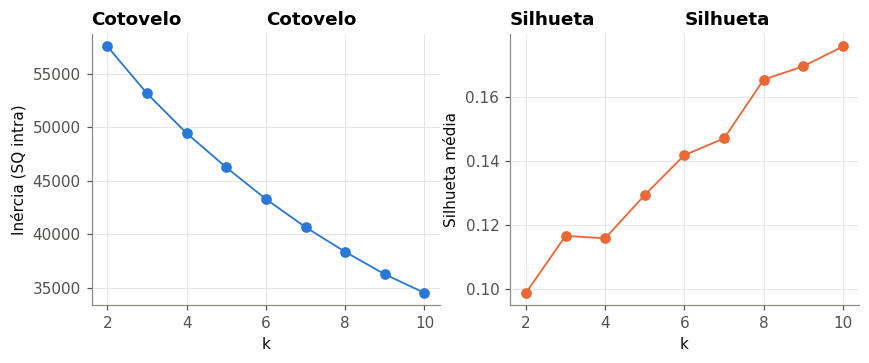

In [3]:
tabela_k = ag.select_k(Z, k_range=range(2, 11))
vz.plot_k_selection(tabela_k)
tabela_k.round(3)

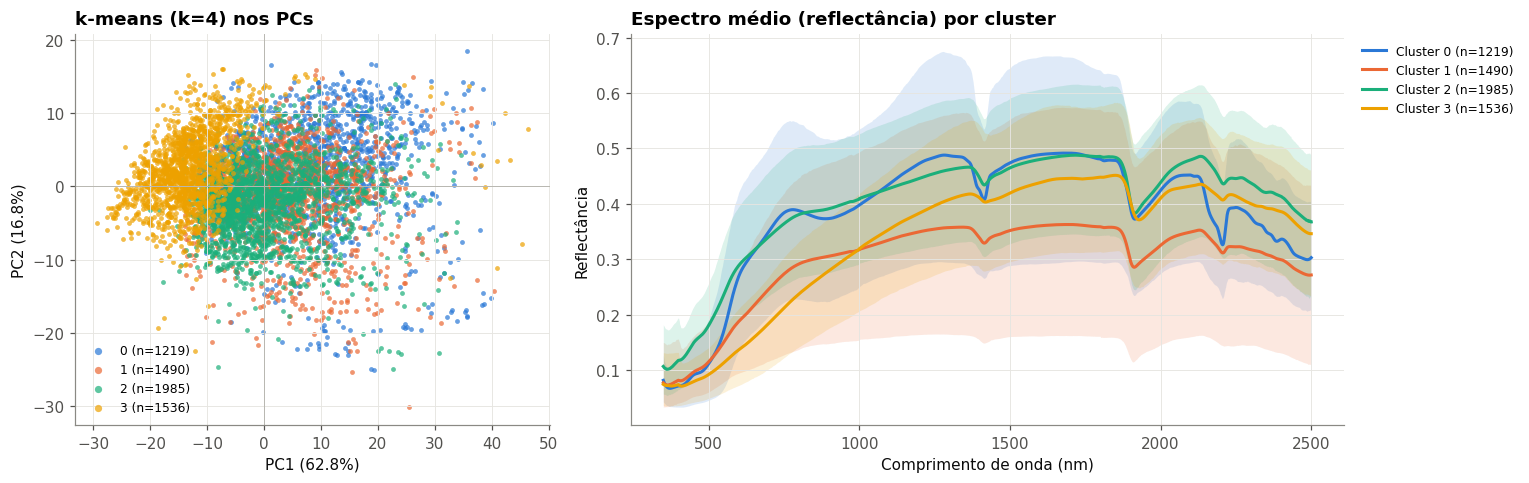

In [4]:
K = 4   # ajuste após olhar a tabela acima
rotulos, modelo = ag.kmeans(Z, K)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
vz.plot_scores(pca.scores, color_by=rotulos.astype("category"), explained=pca.explained, ax=axes[0],
               title=f"k-means (k={K}) nos PCs")
vz.plot_cluster_means(ds.vnir, rotulos, ax=axes[1], title="Espectro médio (reflectância) por cluster")
fig.tight_layout()

### Interpretando os clusters com os atributos

In [5]:
perfil = ag.cluster_profile(rotulos, ds.attributes[[c for c in ["Clay_gkg", "Sand_gkg", "C_gkg", "pH_H2O"] if c in ds.attributes]])
perfil

,n,Clay_gkg,Sand_gkg,C_gkg,pH_H2O
cluster,,,,,
0,1219,449.3,356.2,15.0,5.5
1,1490,328.2,382.3,27.2,6.6
2,1985,274.5,296.1,9.6,7.3
3,1536,204.2,476.4,205.3,6.1


In [6]:
pd.crosstab(rotulos, ds.meta["Textura"], normalize="index").round(2)

Textura,Arenosa,Média,Argilosa,Muito argilosa
cluster,,,,
0,0.04,0.32,0.39,0.25
1,0.10,0.48,0.28,0.14
2,0.07,0.61,0.28,0.04
3,0.23,0.58,0.16,0.04


### k-means "angular"
Com `angular=True` cada espectro é normalizado pela norma antes do k-means; o agrupamento
passa a depender da **forma** do espectro (como o SAM), não do brilho.

In [7]:
rot_ang, _ = ag.kmeans(pp.trim(ds.vnir, 400, 2450), K, angular=True)
pd.crosstab(rotulos.rename("k-means PCs"), rot_ang.rename("k-means angular"))

k-means angular,0,1,2,3
k-means PCs,,,,
0,253,82,233,651
1,581,40,659,210
2,627,20,1267,71
3,17,1171,326,22


## 3. ISODATA
Variante do k-means que **ajusta o número de clusters** durante as iterações:
- elimina clusters com menos de `min_samples` amostras;
- **divide** clusters muito dispersos (DP numa dimensão > `max_std`);
- **funde** clusters cujos centros estão mais próximos que `min_dist`.

É o algoritmo não supervisionado clássico do sensoriamento remoto (ENVI, ERDAS).

In [8]:
iso = ag.isodata(Z.to_numpy(), k_init=8, k_desired=5, min_samples=50, max_iter=40)
print("nº de clusters por iteração:", iso.history)
rot_iso = pd.Series(iso.labels, index=Z.index, name="isodata")
print("clusters finais:", iso.n_clusters)
pd.crosstab(rot_iso, rotulos.rename("kmeans"))

nº de clusters por iteração: [10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 9, 10, 10, 9, 8, 10, 9, 10, 9, 10, 8, 10, 8, 10, 8, 10, 9, 10, 9]
clusters finais: 9


kmeans,0,1,2,3
isodata,,,,
0,656,18,34,4
1,61,11,7,0
2,1,278,13,12
3,44,32,6,5
4,0,430,23,41
5,55,35,96,17
6,224,29,43,5
7,110,230,26,10
8,68,427,1737,1442


**Sensibilidade aos parâmetros.** O número final de clusters fica entre K/2 e 2K e depende
sobretudo de `max_std` (quando dividir) e `min_dist` (quando fundir). Espectros de solo formam
um **contínuo** (veja a silhueta baixa na seção 2), então o ISODATA tende a oscilar entre
dividir e fundir — os limiares é que definem a "resolução" do agrupamento.

In [9]:
pd.DataFrame([{"max_std": s, "clusters_finais": ag.isodata(Z.to_numpy(), k_init=8, k_desired=5,
                                                        min_samples=50, max_std=s).n_clusters}
              for s in (0.8, 1.0, 1.5, 2.0, 3.0)])

,max_std,clusters_finais
0,0.8,10
1,1.0,9
2,1.5,9
3,2.0,2
4,3.0,2


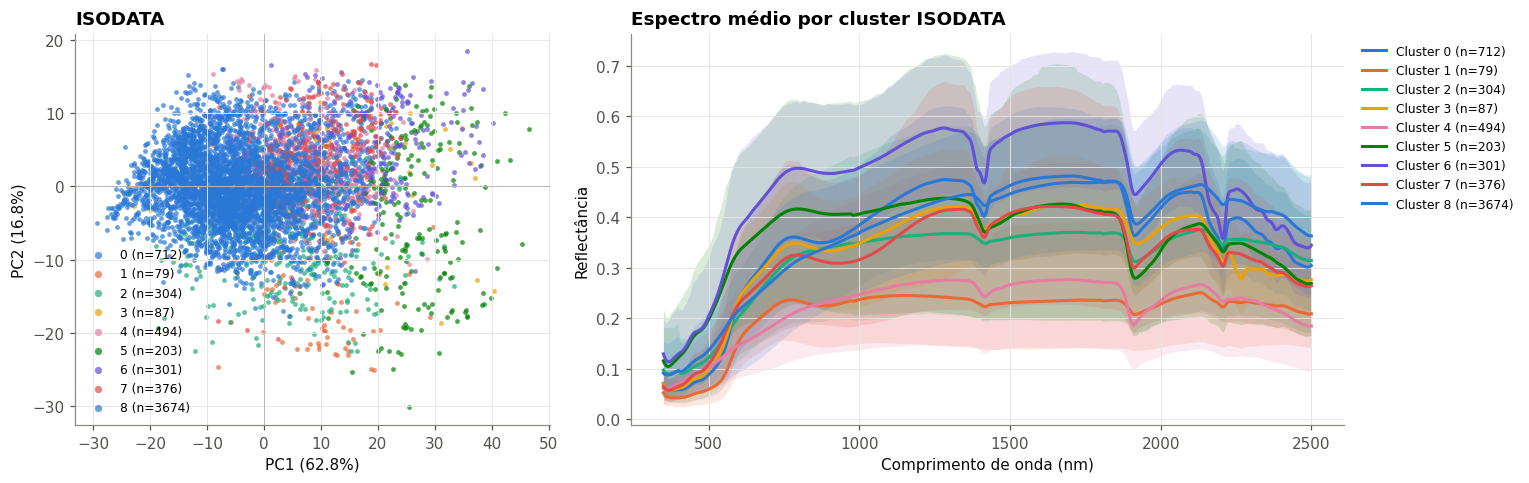

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
vz.plot_scores(pca.scores, color_by=rot_iso.astype("category"), explained=pca.explained, ax=axes[0], title="ISODATA")
vz.plot_cluster_means(ds.vnir, rot_iso, ax=axes[1], title="Espectro médio por cluster ISODATA")
fig.tight_layout()

## 4. Métricas de similaridade espectral

| Métrica | Fórmula (ideia) | Sensível a albedo? | Interpretação |
|---|---|---|---|
| Euclidiana | ‖a − b‖ | **sim** | diferença absoluta |
| SAM | arccos(a·b / ‖a‖‖b‖) | não (escala) | ângulo, 0 = mesma forma |
| SCM | r de Pearson | não (escala e deslocamento) | 1 = mesma forma |
| SID | divergência KL simétrica | não (escala) | 0 = mesma "distribuição" |

Demonstração: um espectro e o mesmo espectro 30 % mais escuro.

In [11]:
a = ds.vnir.iloc[0].to_numpy()
b = 0.7 * a
c = ds.vnir.iloc[1].to_numpy()
pd.DataFrame({
    "mesma amostra, 30% mais escura": [ag.euclidean(a, b), ag.sam(a, b), ag.spectral_correlation(a, b), ag.sid(a, b)],
    "outra amostra": [ag.euclidean(a, c), ag.sam(a, c), ag.spectral_correlation(a, c), ag.sid(a, c)],
}, index=["Euclidiana", "SAM (rad)", "SCM (r)", "SID"]).round(4)

,"mesma amostra, 30% mais escura",outra amostra
Euclidiana,3.2027,3.8923
SAM (rad),0.0000,0.0242
SCM (r),1.0000,0.9946
SID,0.0000,0.0009


## 5. Classificação por espectros de referência
Com espectros-referência (médias de classes conhecidas, bibliotecas, endmembers) cada
amostra recebe a classe mais similar. Aqui usamos o espectro médio de cada classe
textural como referência e verificamos a concordância.

In [12]:
Xv = pp.trim(ds.vnir, 400, 2450)
refs = Xv.groupby(ds.meta["Textura"], observed=True).mean()
resultados = {}
for metrica in ["euclidean", "sam", "scm", "sid"]:
    cls = ag.classify_by_reference(Xv, refs, metric=metrica)
    ok = ds.meta["Textura"].notna()
    resultados[metrica] = (cls.loc[ok, "classe"].astype(str) == ds.meta.loc[ok, "Textura"].astype(str)).mean()
pd.Series(resultados, name="concordância com a classe textural").round(3)

euclidean    0.253
sam          0.363
scm          0.340
sid          0.368
Name: concordância com a classe textural, dtype: float64

Concordâncias baixas são esperadas: a textura não é o único fator que controla o espectro
(mineralogia, MO, umidade, equipamento). O exercício mostra **como** comparar métricas.

## Exercícios
1. Refaça o k-means no **MIR** (SNV → PCA). Os grupos coincidem com os do VIS–NIR–SWIR?
2. Rode ISODATA com `min_samples` 20 e 150. Como muda o número final de clusters?
3. Use os espectros médios dos clusters k-means como referência e classifique com SAM.
   Qual a concordância com os próprios rótulos do k-means? Por que não é 100 %?